# PRCP-1020 House Price Prediction


> **Before running:** place `data.csv` at `PRCP-1020-HousePricePred/Data/data.csv`, in the same folder as this notebook.

## Task 1: Data Analysis Report

### Dataset overview
- Ames, Iowa housing data: **1,460 houses** and **80 columns** (37 numeric, 43 categorical). The target is **SalePrice**.
- It mixes numeric features (areas, years, counts) with categorical ones (quality ratings, neighbourhood, house type).

### Missing values
- The columns with the most missing values are PoolQC (99.5%), MiscFeature (96.3%), Alley (93.8%), Fence (80.8%) and FireplaceQu (47.3%).
- In most of these, missing means the feature does not exist, so I filled categorical gaps with "None".
- MasVnrArea was filled with 0, and GarageYrBlt was filled with YearBuilt (a year of 0 would be a fake extreme value; the HasGarage flag already records that there is no garage).

### Key EDA findings
- SalePrice is right-skewed (skewness 1.88), so I modelled the log of the price.
- Strongest correlations with price: OverallQual (0.79), GrLivArea (0.71), GarageCars (0.64), TotalBsmtSF (0.61). My engineered feature TotalSF is higher still (0.83).
- Outliers: 2 very large houses (above 4,000 sq ft GrLivArea) with low prices (under 300k dollars) were removed because they are abnormal sales that distort the model.
- Price varies strongly by Neighborhood.
- Sale condition changes price: Partial sales (new builds) sell for far more than Normal sales, and Abnorml sales for less.
- Median price was flat in 2006–2009 and dropped in 2010.

### Data preparation
- The cleaned data has **1,458 rows**. I created new features (TotalSF, HouseAge, TotalBath and Has... flags), encoded categories, and log-transformed skewed columns. After encoding there are **242 features**.

In [4]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [5]:
df = pd.read_csv("PRCP-1020-HousePricePred/Data/data.csv", keep_default_na=False, na_values=["NA", ""])
df.drop(columns="Id", inplace=True)
print(df.shape)
df.head()

(1460, 80)


,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 80 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   MSSubClass     1460 non-null   int64  
 1   MSZoning       1460 non-null   object 
 2   LotFrontage    1201 non-null   float64
 3   LotArea        1460 non-null   int64  
 4   Street         1460 non-null   object 
 5   Alley          91 non-null     object 
 6   LotShape       1460 non-null   object 
 7   LandContour    1460 non-null   object 
 8   Utilities      1460 non-null   object 
 9   LotConfig      1460 non-null   object 
 10  LandSlope      1460 non-null   object 
 11  Neighborhood   1460 non-null   object 
 12  Condition1     1460 non-null   object 
 13  Condition2     1460 non-null   object 
 14  BldgType       1460 non-null   object 
 15  HouseStyle     1460 non-null   object 
 16  OverallQual    1460 non-null   int64  
 17  OverallCond    1460 non-null   int64  
 18  YearBuil

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0
BsmtFinSF2,1460.0,46.549315,161.319273,0.0,0.00,0.0,0.00,1474.0


In [8]:
num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
print("Numerical:", len(num_cols))
print("Categorical:", len(cat_cols))

Numerical: 37
Categorical: 43


count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64
Skewness: 1.8828757597682129


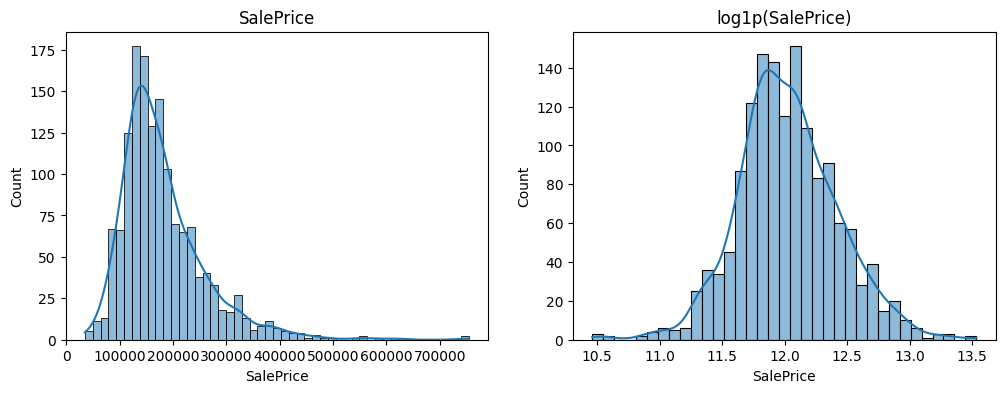

In [9]:
print(df["SalePrice"].describe())
print("Skewness:", df["SalePrice"].skew())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["SalePrice"], kde=True, ax=ax[0])
ax[0].set_title("SalePrice")
sns.histplot(np.log1p(df["SalePrice"]), kde=True, ax=ax[1])
ax[1].set_title("log1p(SalePrice)")
plt.show()

              Missing  Percent
PoolQC           1453    99.52
MiscFeature      1406    96.30
Alley            1369    93.77
Fence            1179    80.75
FireplaceQu       690    47.26
LotFrontage       259    17.74
GarageType         81     5.55
GarageYrBlt        81     5.55
GarageFinish       81     5.55
GarageQual         81     5.55
GarageCond         81     5.55
BsmtExposure       38     2.60
BsmtFinType2       38     2.60
BsmtFinType1       37     2.53
BsmtCond           37     2.53
BsmtQual           37     2.53
MasVnrArea          8     0.55
MasVnrType          8     0.55
Electrical          1     0.07


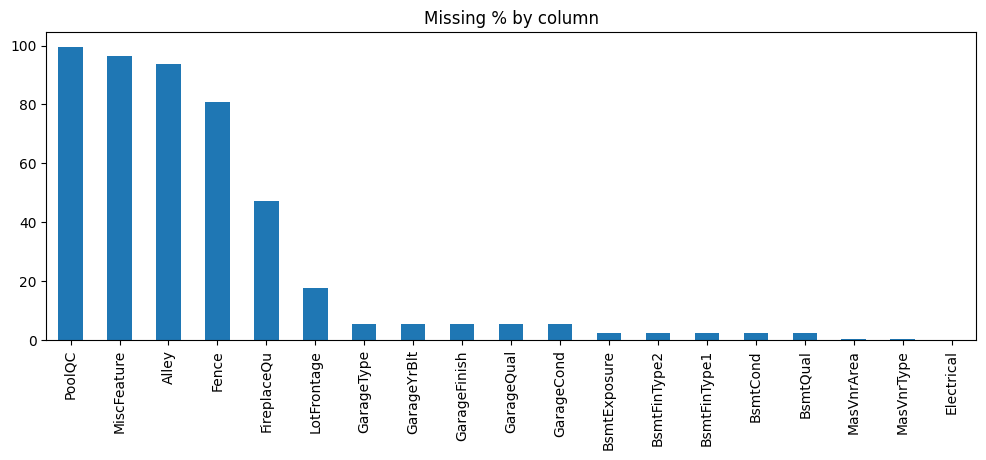

In [10]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
print(pd.DataFrame({"Missing": missing, "Percent": missing_pct}))

missing_pct.plot(kind="bar", figsize=(12, 4), title="Missing % by column")
plt.show()

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64


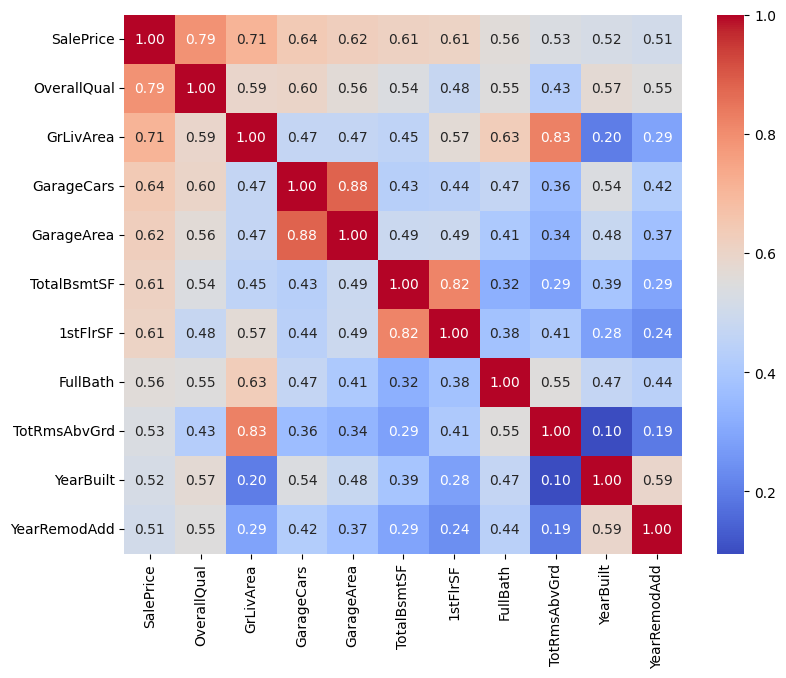

In [11]:
corr = df[num_cols].corr()["SalePrice"].sort_values(ascending=False)
print(corr.head(11))

top = corr.head(11).index
plt.figure(figsize=(9, 7))
sns.heatmap(df[top].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

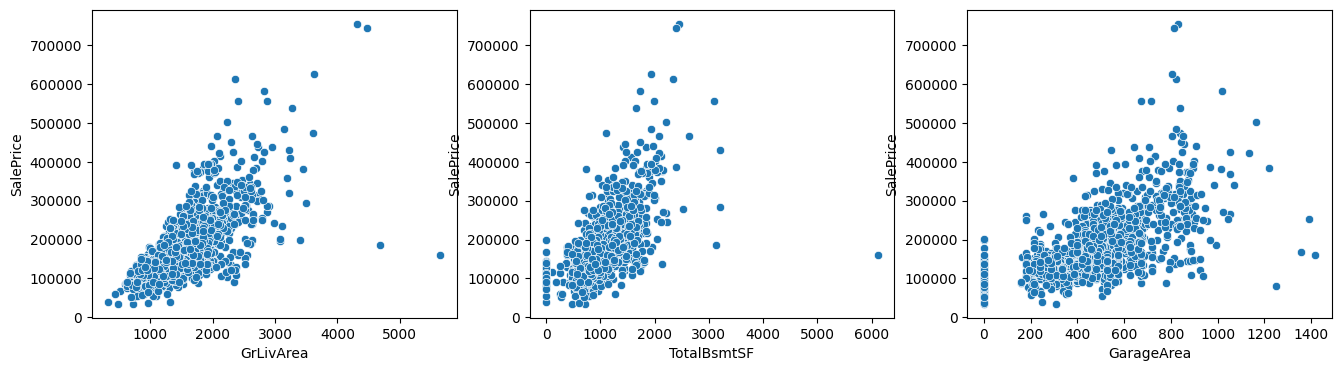

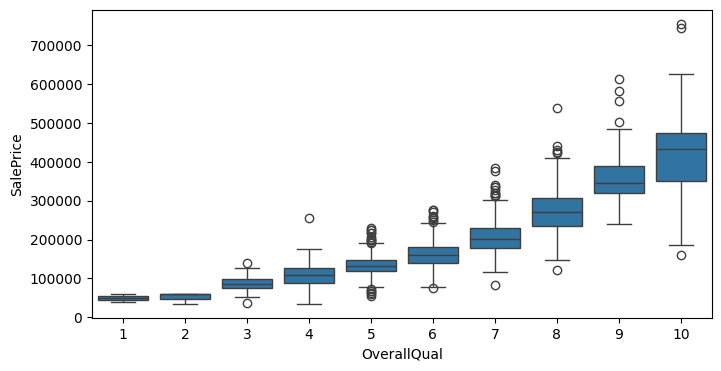

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, col in zip(ax, ["GrLivArea", "TotalBsmtSF", "GarageArea"]):
    sns.scatterplot(x=df[col], y=df["SalePrice"], ax=a)
plt.show()

plt.figure(figsize=(8, 4))
sns.boxplot(x="OverallQual", y="SalePrice", data=df)
plt.show()

In [13]:
outliers = df[(df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)]
print(outliers[["GrLivArea", "TotalBsmtSF", "SalePrice"]])

      GrLivArea  TotalBsmtSF  SalePrice
523        4676         3138     184750
1298       5642         6110     160000


In [14]:
df = df[~((df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000))].reset_index(drop=True)
print(df.shape)

(1458, 80)


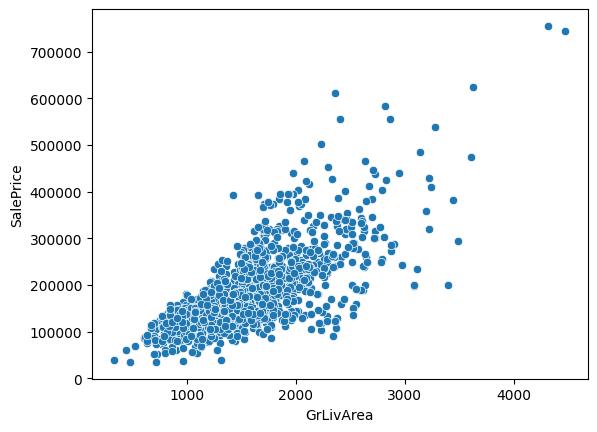

In [15]:
sns.scatterplot(x=df["GrLivArea"], y=df["SalePrice"])
plt.show()

In [16]:
# Categorical columns where missing means "does not exist"
none_cols = ["PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
             "GarageType", "GarageFinish", "GarageQual", "GarageCond",
             "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
             "MasVnrType"]
for c in none_cols:
    df[c] = df[c].fillna("None")

df["MasVnrArea"] = df["MasVnrArea"].fillna(0)
df["GarageYrBlt"] = df["GarageYrBlt"].fillna(df["YearBuilt"])  

In [17]:
# LotFrontage: median of the same neighborhood
df["LotFrontage"] = df.groupby("Neighborhood")["LotFrontage"].transform(lambda x: x.fillna(x.median()))

# Electrical: only 1 missing, use the most common value
df["Electrical"] = df["Electrical"].fillna(df["Electrical"].mode()[0])

In [18]:
print("Total missing:", df.isnull().sum().sum())

Total missing: 0


In [19]:
df["MSSubClass"] = df["MSSubClass"].astype(str)
df["MoSold"] = df["MoSold"].astype(str)
print(df[["MSSubClass", "MoSold"]].dtypes)

MSSubClass    object
MoSold        object
dtype: object


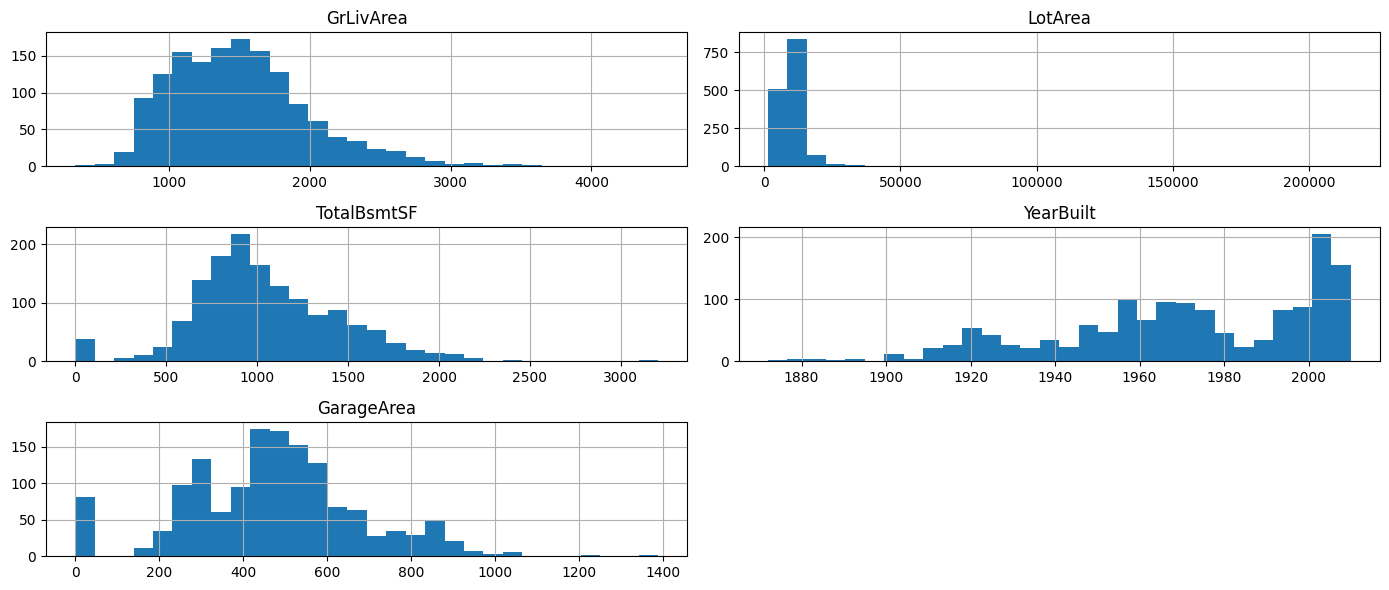

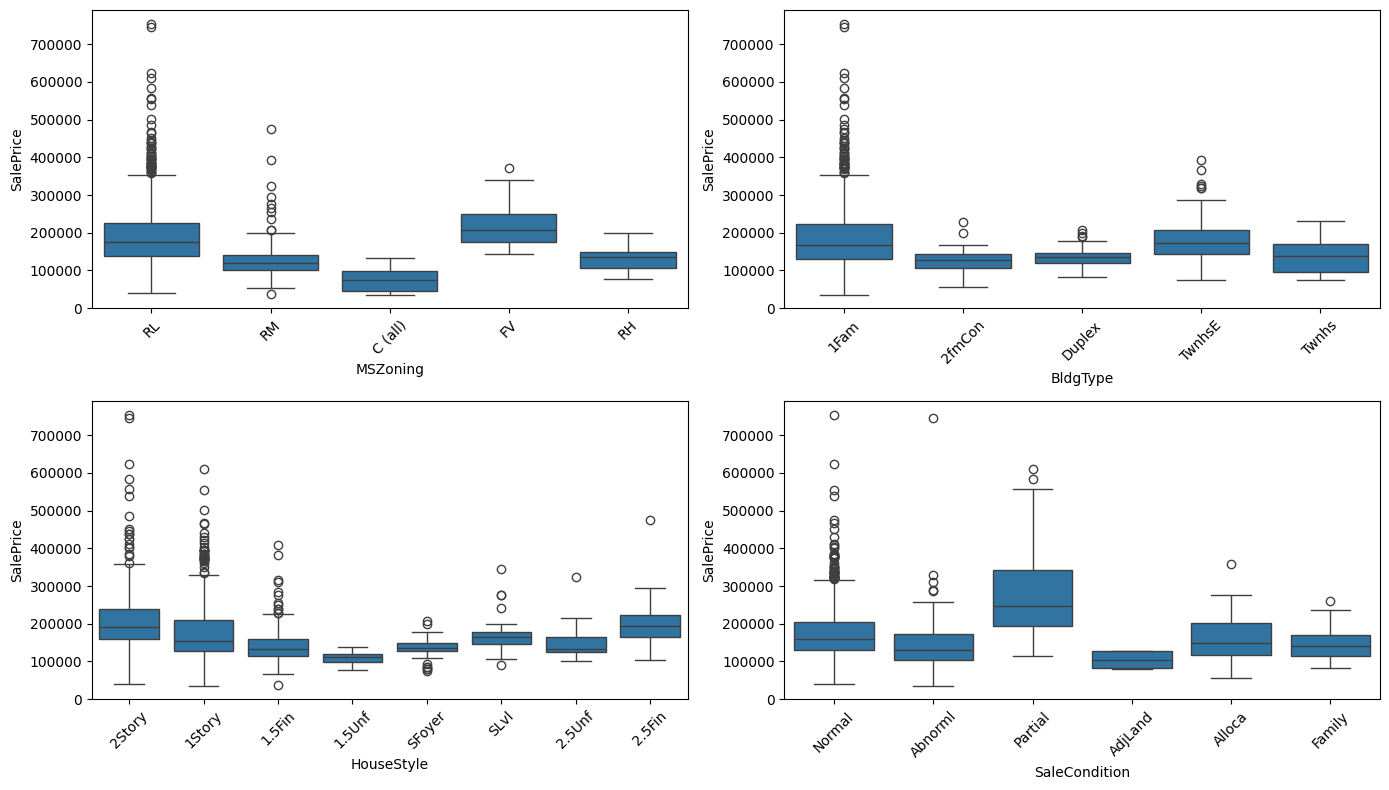

YrSold
2006    163995.0
2007    166000.0
2008    165000.0
2009    162000.0
2010    155000.0
Name: SalePrice, dtype: float64


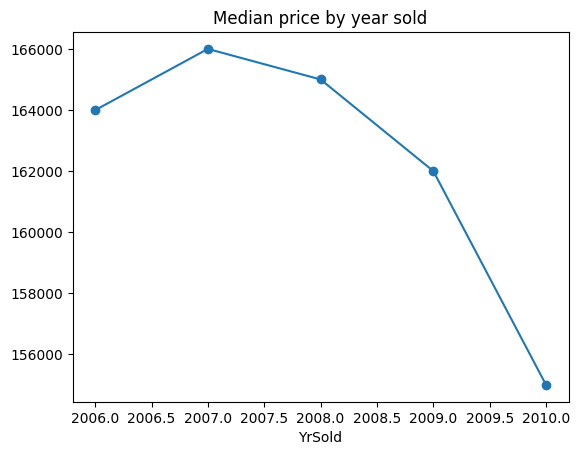

              GarageCars  GarageArea  TotalBsmtSF  1stFlrSF  GrLivArea  \
GarageCars          1.00        0.89         0.45      0.45       0.48   
GarageArea          0.89        1.00         0.48      0.48       0.46   
TotalBsmtSF         0.45        0.48         1.00      0.80       0.41   
1stFlrSF            0.45        0.48         0.80      1.00       0.53   
GrLivArea           0.48        0.46         0.41      0.53       1.00   
TotRmsAbvGrd        0.36        0.33         0.27      0.40       0.83   

              TotRmsAbvGrd  
GarageCars            0.36  
GarageArea            0.33  
TotalBsmtSF           0.27  
1stFlrSF              0.40  
GrLivArea             0.83  
TotRmsAbvGrd          1.00  


In [20]:
# Distributions of key numeric features
df[["GrLivArea", "LotArea", "TotalBsmtSF", "YearBuilt", "GarageArea"]].hist(bins=30, figsize=(14, 6))
plt.tight_layout(); plt.show()

# Price vs key categoricals
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
for a, col in zip(ax.ravel(), ["MSZoning", "BldgType", "HouseStyle", "SaleCondition"]):
    sns.boxplot(x=col, y="SalePrice", data=df, ax=a)
    a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

# Market trend over time
print(df.groupby("YrSold")["SalePrice"].median())
df.groupby("YrSold")["SalePrice"].median().plot(marker="o", title="Median price by year sold")
plt.show()

# Multicollinearity check
print(df[["GarageCars", "GarageArea", "TotalBsmtSF", "1stFlrSF", "GrLivArea", "TotRmsAbvGrd"]].corr().round(2))

**What the new charts show**
- **Price by category:** FV zoning has the highest median price (about &#36;205k) and C (all) the lowest (about &#36;75k). 2Story and 2.5Fin houses sell highest, and 1.5Unf lowest. 1Fam homes have the widest price range, with many high outliers.
- **Sale condition matters:** Partial sales (mostly new builds) have a much higher median (about &#36;245k) than Normal sales (about &#36;160k), and Abnorml sales are lower. This is why Task 3 uses Normal sales only.
- **Market trend:** median price was flat from 2006 to 2009 (about &#36;162k–&#36;166k) and fell to &#36;155k in 2010, so the data covers the housing downturn.
- **Multicollinearity:** GarageCars and GarageArea (0.89), GrLivArea and TotRmsAbvGrd (0.83), TotalBsmtSF and 1stFlrSF (0.80) are highly correlated, so regularised models (Ridge, Lasso) suit this data.

## Data Cleaning Summary

| Problem | What I did | Why |
|---|---|---|
| 2 extreme outliers in GrLivArea (above 4000 sq ft, price under $300k) | Removed them | Very large houses with very low prices are abnormal sales and distort the model |
| 15 categorical columns with missing values (PoolQC, MiscFeature, Alley, Fence, FireplaceQu, Garage and Basement columns, MasVnrType) | Filled with "None" | Missing means the feature does not exist, so "None" is a real category |
| MasVnrArea had missing values | Filled with 0 | No veneer means no veneer area |
| GarageYrBlt had missing values | Filled with YearBuilt | A year of 0 would be an extreme fake value; the HasGarage flag already records that there is no garage |
| LotFrontage had 259 missing values | Filled with the median of the same Neighborhood | Lots in the same area have similar frontage |
| Electrical had 1 missing value | Filled with the mode | Keeps the most common category without adding bias |
| MSSubClass and MoSold stored as numbers | Converted to text | They are labels (building class, month), not quantities |

**Result:** the dataset now has 1458 rows, 80 columns and no missing values.

In [23]:
df.shape

(1458, 80)

In [24]:
df["TotalSF"] = df["TotalBsmtSF"] + df["1stFlrSF"] + df["2ndFlrSF"]
df["HouseAge"] = df["YrSold"] - df["YearBuilt"]
df["RemodAge"] = df["YrSold"] - df["YearRemodAdd"]
df["TotalBath"] = df["FullBath"] + 0.5*df["HalfBath"] + df["BsmtFullBath"] + 0.5*df["BsmtHalfBath"]
df["TotalPorchSF"] = df["OpenPorchSF"] + df["EnclosedPorch"] + df["3SsnPorch"] + df["ScreenPorch"]
df["HasPool"] = (df["PoolArea"] > 0).astype(int)
df["HasGarage"] = (df["GarageArea"] > 0).astype(int)
df["HasFireplace"] = (df["Fireplaces"] > 0).astype(int)
df["HasBasement"] = (df["TotalBsmtSF"] > 0).astype(int)

print(df[["TotalSF", "HouseAge", "TotalBath"]].describe())

           TotalSF     HouseAge    TotalBath
count  1458.000000  1458.000000  1458.000000
mean   2557.150206    36.598080     2.207476
std     774.109803    30.240565     0.781341
min     334.000000     0.000000     1.000000
25%    2008.500000     8.000000     2.000000
50%    2473.000000    35.000000     2.000000
75%    3002.250000    54.000000     2.500000
max    6872.000000   136.000000     6.000000


In [25]:
print(df[["TotalSF", "HouseAge", "RemodAge", "TotalBath", "SalePrice"]].corr()["SalePrice"])

TotalSF      0.832877
HouseAge    -0.524067
RemodAge    -0.509706
TotalBath    0.635896
SalePrice    1.000000
Name: SalePrice, dtype: float64


**Feature engineering result:** TotalSF has a correlation of 0.833 with SalePrice, higher than GrLivArea alone (0.709), so the combined feature helped. TotalBath (0.636) is stronger than the individual bath columns, and HouseAge (-0.524) and RemodAge (-0.510) show that newer houses sell for more.

In [27]:
qual_map = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
qual_cols = ["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC",
             "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"]
for c in qual_cols:
    df[c] = df[c].map(qual_map)

df["BsmtExposure"] = df["BsmtExposure"].map({"None": 0, "No": 1, "Mn": 2, "Av": 3, "Gd": 4})
fin_map = {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6}
df["BsmtFinType1"] = df["BsmtFinType1"].map(fin_map)
df["BsmtFinType2"] = df["BsmtFinType2"].map(fin_map)
df["GarageFinish"] = df["GarageFinish"].map({"None": 0, "Unf": 1, "RFn": 2, "Fin": 3})
df["LandSlope"] = df["LandSlope"].map({"Gtl": 1, "Mod": 2, "Sev": 3})
df["CentralAir"] = df["CentralAir"].map({"N": 0, "Y": 1})

print("Missing after mapping:", df.isnull().sum().sum())

Missing after mapping: 0


In [28]:
print(df["Utilities"].value_counts())
print(df["Street"].value_counts())

Utilities
AllPub    1457
NoSeWa       1
Name: count, dtype: int64
Street
Pave    1452
Grvl       6
Name: count, dtype: int64


In [29]:
df.drop(columns=["Utilities", "Street"], inplace=True)

In [30]:
from scipy.stats import skew

skew_cols = ["LotFrontage", "LotArea", "MasVnrArea", "BsmtFinSF1", "BsmtUnfSF",
             "TotalBsmtSF", "1stFlrSF", "2ndFlrSF", "GrLivArea", "WoodDeckSF",
             "OpenPorchSF", "TotalSF", "TotalPorchSF"]
skews = df[skew_cols].apply(lambda x: skew(x)).sort_values(ascending=False)
print(skews)

LotArea         12.560986
MasVnrArea       2.693554
OpenPorchSF      2.337421
TotalPorchSF     2.009401
LotFrontage      1.546624
WoodDeckSF       1.544214
GrLivArea        1.009951
BsmtUnfSF        0.919955
1stFlrSF         0.886723
2ndFlrSF         0.812121
TotalSF          0.803494
BsmtFinSF1       0.764002
TotalBsmtSF      0.511177
dtype: float64


In [31]:
high_skew = skews[skews > 0.75].index
for c in high_skew:
    df[c] = np.log1p(df[c])
print("Transformed:", list(high_skew))

Transformed: ['LotArea', 'MasVnrArea', 'OpenPorchSF', 'TotalPorchSF', 'LotFrontage', 'WoodDeckSF', 'GrLivArea', 'BsmtUnfSF', '1stFlrSF', '2ndFlrSF', 'TotalSF', 'BsmtFinSF1']


In [32]:
cat_left = df.select_dtypes(exclude="number").columns.tolist()
print(len(cat_left), cat_left)

df_encoded = pd.get_dummies(df, columns=cat_left, drop_first=True)
print(df_encoded.shape)

27 ['MSSubClass', 'MSZoning', 'Alley', 'LotShape', 'LandContour', 'LotConfig', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'Foundation', 'Heating', 'Electrical', 'Functional', 'GarageType', 'PavedDrive', 'Fence', 'MiscFeature', 'MoSold', 'SaleType', 'SaleCondition']
(1458, 243)


**What was created and why**
- TotalSF: combined basement, first and second floor area (one strong size feature).
- HouseAge and RemodAge: age at sale matters more than the raw year.
- TotalBath: combines four bath columns.
- TotalPorchSF and the Has... flags (HasPool, HasGarage, HasFireplace, HasBasement): simplify sparse columns.

**Encoding:** ordinal mapping for ordered ratings, one-hot encoding for unordered categories (27 columns, giving 242 features), and log1p transforms for numeric columns with skew above 0.75.

In [34]:
df_encoded = df_encoded.astype(float)   # makes the True/False dummy columns numeric

X = df_encoded.drop(columns="SalePrice")
y = np.log1p(df_encoded["SalePrice"])   # model the log of the price

print(X.shape, y.shape)

(1458, 242) (1458,)


In [35]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)   # fit on train only
X_test_sc = scaler.transform(X_test)

print(X_train.shape, X_test.shape)

(1166, 242) (292, 242)


In [36]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=10),
    "Lasso": Lasso(alpha=0.001),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=500, learning_rate=0.05, max_depth=3, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=3, random_state=42),
}
linear_models = ["Linear Regression", "Ridge", "Lasso"]

In [37]:
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

kf = KFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, model in models.items():
    # linear models use scaled data, tree models use raw data
    Xtr, Xte = (X_train_sc, X_test_sc) if name in linear_models else (X_train, X_test)
    model.fit(Xtr, y_train)

    train_pred, test_pred = model.predict(Xtr), model.predict(Xte)
    cv_rmse = np.sqrt(-cross_val_score(model, Xtr, y_train, cv=kf,
                                       scoring="neg_mean_squared_error")).mean()
    results.append({
        "Model": name,
        "Train R2": r2_score(y_train, train_pred),
        "Test R2": r2_score(y_test, test_pred),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, test_pred)),
        "Test MAE": mean_absolute_error(y_test, test_pred),
        "CV RMSE": cv_rmse,
    })

results_df = pd.DataFrame(results).sort_values("CV RMSE").reset_index(drop=True)
results_df.round(4)

,Model,Train R2,Test R2,Test RMSE,Test MAE,CV RMSE
0,Lasso,0.9434,0.9103,0.1230,0.0831,0.1184
1,XGBoost,0.9787,0.9121,0.1217,0.0823,0.1203
2,Gradient Boosting,0.9817,0.9127,0.1213,0.0825,0.1211
3,Ridge,0.9480,0.9067,0.1254,0.0877,0.1244
4,Random Forest,0.9843,0.8750,0.1452,0.0959,0.1350
5,Linear Regression,0.9496,0.8943,0.1335,0.0906,0.1568


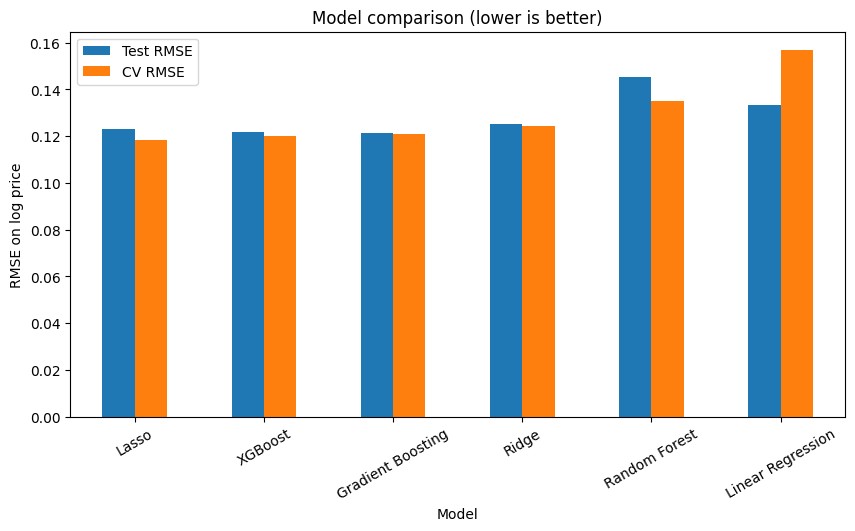

In [38]:
results_df.set_index("Model")[["Test RMSE", "CV RMSE"]].plot(kind="bar", figsize=(10, 5))
plt.title("Model comparison (lower is better)")
plt.ylabel("RMSE on log price")
plt.xticks(rotation=30)
plt.show()

## Model Comparison (before tuning)
- Lasso had the lowest CV RMSE (about 0.118 on log price), followed by XGBoost (0.120) and Gradient Boosting (0.121).
- Linear Regression had the worst CV RMSE (about 0.157), because 242 highly correlated features make its coefficients unstable. Ridge and Lasso fix this with regularisation.
- Random Forest had the highest test RMSE (0.145), so it generalises less well than the other models here.
- Train R² vs Test R² gap: Lasso has the smallest gap (0.943 vs 0.910). Gradient Boosting (0.982 vs 0.913) and XGBoost (0.979 vs 0.912) overfit slightly. Random Forest overfits the most (0.984 vs 0.875).

In [40]:
from sklearn.model_selection import GridSearchCV

top3 = ["Lasso", "Gradient Boosting", "XGBoost"]
param_grids = {
    "Lasso": {"alpha": [0.0003, 0.001, 0.003, 0.01]},
    "Gradient Boosting": {"n_estimators": [300, 500],
                          "learning_rate": [0.03, 0.05],
                          "max_depth": [2, 3],
                          "subsample": [0.8, 1.0]},
    "XGBoost": {"n_estimators": [300, 500],
                "learning_rate": [0.03, 0.05],
                "max_depth": [2, 3],
                "subsample": [0.8, 1.0]},
}

tuned, cv_scores = {}, {}
for name in top3:
    Xtr = X_train_sc if name in linear_models else X_train
    gs = GridSearchCV(models[name], param_grids[name], cv=5,
                      scoring="neg_mean_squared_error", n_jobs=-1)
    gs.fit(Xtr, y_train)
    tuned[name] = gs.best_estimator_
    cv_scores[name] = np.sqrt(-gs.best_score_)
    print(name, "| best params:", gs.best_params_, "| CV RMSE:", cv_scores[name].round(4))

Lasso | best params: {'alpha': 0.003} | CV RMSE: 0.1176
Gradient Boosting | best params: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 500, 'subsample': 0.8} | CV RMSE: 0.1191
XGBoost | best params: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 500, 'subsample': 0.8} | CV RMSE: 0.12


In [41]:
final = []
for name, model in tuned.items():
    Xte = X_test_sc if name in linear_models else X_test
    pred = model.predict(Xte)
    final.append({"Model": name + " (tuned)",
                  "Test R2": r2_score(y_test, pred),
                  "Test RMSE": np.sqrt(mean_squared_error(y_test, pred)),
                  "Test MAE": mean_absolute_error(y_test, pred),
                  "Test MAE ($)": mean_absolute_error(np.expm1(y_test), np.expm1(pred))})
final_df = pd.DataFrame(final).sort_values("Test RMSE").reset_index(drop=True)
final_df.round(4)

,Model,Test R2,Test RMSE,Test MAE,Test MAE ($)
0,Lasso (tuned),0.9155,0.1193,0.0813,14217.5026
1,Gradient Boosting (tuned),0.9130,0.1211,0.0803,13391.0134
2,XGBoost (tuned),0.9121,0.1218,0.0824,14096.0372


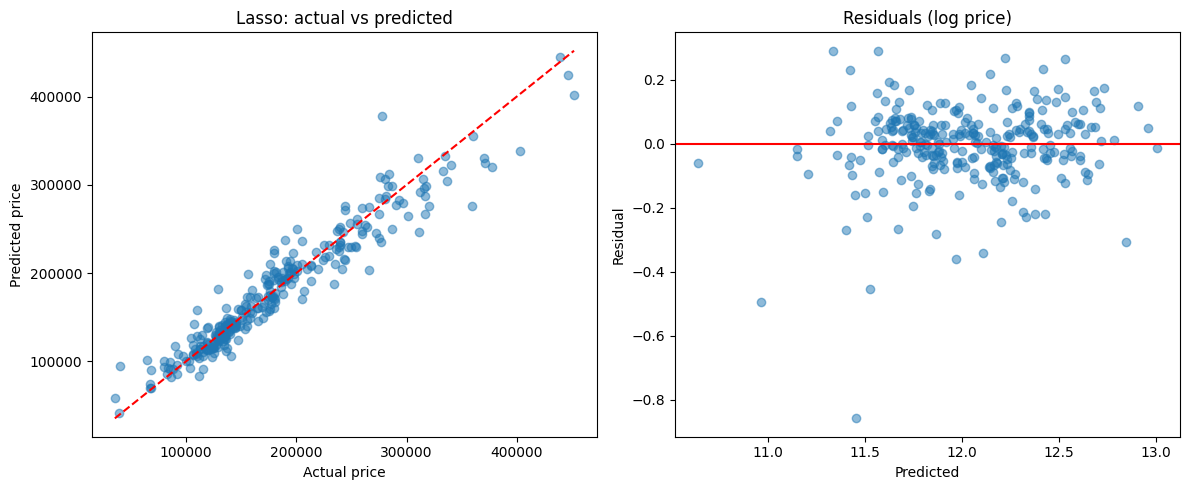

Best model: Lasso


In [42]:
import joblib

best_name = min(cv_scores, key=cv_scores.get) 
best_model = tuned[best_name]
Xte_best = X_test_sc if best_name in linear_models else X_test
pred = best_model.predict(Xte_best)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(np.expm1(y_test), np.expm1(pred), alpha=0.5)
lims = [np.expm1(y_test).min(), np.expm1(y_test).max()]
ax[0].plot(lims, lims, "r--"); ax[0].set_title(f"{best_name}: actual vs predicted")
ax[0].set_xlabel("Actual price"); ax[0].set_ylabel("Predicted price")
ax[1].scatter(pred, y_test - pred, alpha=0.5); ax[1].axhline(0, color="r")
ax[1].set_title("Residuals (log price)"); ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("Residual")
plt.tight_layout(); plt.show()
joblib.dump(list(X.columns), "feature_columns.pkl")
print("Best model:", best_name)

In [43]:
from sklearn.pipeline import Pipeline
from sklearn.base import clone

if best_name in linear_models:
    final_model = Pipeline([("scaler", StandardScaler()),
                            ("model", clone(tuned[best_name]))])
else:
    final_model = clone(tuned[best_name])

final_model.fit(X_train, y_train)          # raw X: the scaler now lives inside the pipeline
pred = final_model.predict(X_test)
print("Test R2:", r2_score(y_test, pred), "| Test RMSE:", np.sqrt(mean_squared_error(y_test, pred)))

feature_cols = list(X.columns)
joblib.dump(final_model, "house_price_model.pkl")
joblib.dump(feature_cols, "feature_columns.pkl")

def predict_price(new_X):
    """new_X: DataFrame already cleaned/encoded like the training data."""
    new_X = new_X.reindex(columns=feature_cols, fill_value=0)
    return np.expm1(final_model.predict(new_X))

print(predict_price(X_test.head(3)).round(0))

Test R2: 0.9155067379806988 | Test RMSE: 0.11934638006882281
[237056. 100544. 105710.]


## Task 2a Conclusion

- **Best model after tuning:** Lasso (alpha = 0.003), selected using the lowest 5-fold CV RMSE (0.1176) on the training set. On the held-out test set it gives R² = 0.9155 and RMSE = 0.1193 on log price, an average error (MAE) of about \$14,218.
- **The top three models are very close.** Tuned Lasso, Gradient Boosting and XGBoost differ by only about 0.002 RMSE (CV 0.1176, 0.1191, 0.1200), so the gap is small. I choose Lasso because it has the best CV score, a small train/test gap, fast training and easy-to-explain coefficients. Gradient Boosting has the lowest dollar error (MAE \$13,391) and is a good backup.
- **Feature selection:** Lasso set 140 of the 242 feature coefficients to zero, so a smaller set of features explains most of the price variation.
- **Leakage control:** the final model is a single Pipeline (scaler plus model), so the scaler is fitted on training data only. The test set was used only for final reporting, not for choosing the model.

## Task 2b: Relationship between features and price

- **Tree-based importance (XGBoost):** OverallQual, TotalSF, ExterQual, KitchenQual and GarageCars are the strongest drivers of price.
- **Lasso coefficients (the final model):** the biggest positive effects are GrLivArea, OverallQual, TotalBsmtSF, OverallCond and LotArea. Because the target is log price, a coefficient of 0.107 means roughly +11% price per 1 standard deviation increase in living area.
- **Negative effects:** HouseAge (-0.052) is the strongest, so older houses sell for less. KitchenAbvGr and RemodAge also lower price.
- **Neighbourhood matters:** median price rises from about 100k in the cheapest areas to over 300k in NridgHt and NoRidge. Median price also rises steadily with OverallQual, from about 50k at quality 1 to about 445k at quality 10.
- Lasso removed 140 of 242 features, which shows that a smaller set of features explains most of the price.

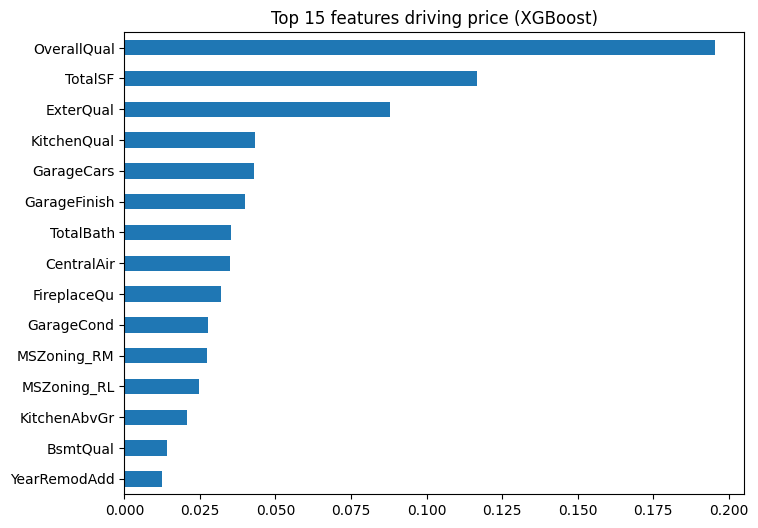

OverallQual     0.1955
TotalSF         0.1168
ExterQual       0.0879
KitchenQual     0.0433
GarageCars      0.0429
GarageFinish    0.0398
TotalBath       0.0353
CentralAir      0.0349
FireplaceQu     0.0319
GarageCond      0.0278
MSZoning_RM     0.0272
MSZoning_RL     0.0247
KitchenAbvGr    0.0208
BsmtQual        0.0141
YearRemodAdd    0.0124
dtype: float32


In [46]:
tree_name = "XGBoost" if "XGBoost" in tuned else "Gradient Boosting"
imp = pd.Series(tuned[tree_name].feature_importances_, index=X.columns).sort_values(ascending=False).head(15)
imp.sort_values().plot(kind="barh", figsize=(8, 6), title=f"Top 15 features driving price ({tree_name})")
plt.show()
print(imp.round(4))

In [47]:
coef = pd.Series(tuned["Lasso"].coef_, index=X.columns)
print("Features zeroed out by Lasso:", (coef == 0).sum())
print("Top positive:\n", coef.sort_values(ascending=False).head(10).round(3))
print("Top negative:\n", coef.sort_values().head(10).round(3))

Features zeroed out by Lasso: 140
Top positive:
 GrLivArea               0.107
OverallQual             0.067
TotalBsmtSF             0.040
OverallCond             0.040
LotArea                 0.038
TotalBath               0.028
SaleType_New            0.027
GarageArea              0.022
Neighborhood_Crawfor    0.020
Neighborhood_StoneBr    0.018
dtype: float64
Top negative:
 HouseAge              -0.052
KitchenAbvGr          -0.014
RemodAge              -0.012
MSSubClass_160        -0.008
Heating_Grav          -0.007
Functional_Maj2       -0.007
GarageType_Basment    -0.006
Exterior1st_BrkComm   -0.006
RoofStyle_Gable       -0.005
Condition1_RRAe       -0.005
dtype: float64


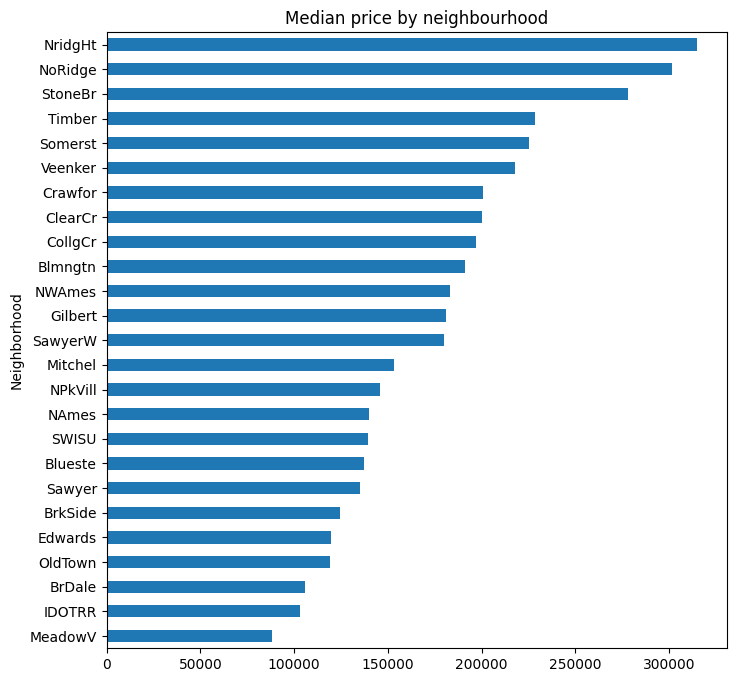

OverallQual
1      50150.0
2      60000.0
3      86250.0
4     108000.0
5     133000.0
6     160000.0
7     200141.0
8     269750.0
9     345000.0
10    445365.0
Name: SalePrice, dtype: float64


In [48]:
raw = df.loc[X.index]
raw.groupby("Neighborhood")["SalePrice"].median().sort_values().plot(
    kind="barh", figsize=(8, 8), title="Median price by neighbourhood")
plt.show()
print(raw.groupby("OverallQual")["SalePrice"].median())

In [49]:
from sklearn.model_selection import cross_val_predict
oof_log = cross_val_predict(final_model, X, y, cv=kf)
all_pred = np.expm1(oof_log)

view = df.loc[X.index, ["Neighborhood", "OverallQual", "BedroomAbvGr", "TotalBath", "HouseAge", "GarageCars"]].copy()
view["TotalSF"] = np.expm1(df.loc[X.index, "TotalSF"]).round(0)   # TotalSF was log-transformed earlier
view["ActualPrice"] = df_encoded["SalePrice"].values
view["PredictedPrice"] = all_pred.round(0)
view["Value_Gap"] = view["PredictedPrice"] - view["ActualPrice"]  
view["SaleCondition"] = df.loc[X.index, "SaleCondition"] # positive = priced below the model's estimate
view.head()

,Neighborhood,OverallQual,BedroomAbvGr,TotalBath,HouseAge,GarageCars,TotalSF,ActualPrice,PredictedPrice,Value_Gap,SaleCondition
0,CollgCr,7,3,3.5,5,2,2566.0,208500.0,204390.0,-4110.0,Normal
1,Veenker,6,3,2.5,31,2,2524.0,181500.0,185349.0,3849.0,Normal
2,CollgCr,7,3,3.5,7,2,2706.0,223500.0,219683.0,-3817.0,Normal
3,Crawfor,7,3,2.0,91,3,2473.0,140000.0,185455.0,45455.0,Abnorml
4,NoRidge,8,4,3.5,8,3,3343.0,250000.0,300867.0,50867.0,Normal


In [50]:
def recommend(budget, min_sf=0, min_bedrooms=0, min_qual=1, neighborhood=None, top_n=5):
    r = view[(view.SaleCondition == "Normal") &
             (view.ActualPrice <= budget) & (view.TotalSF >= min_sf) &
             (view.BedroomAbvGr >= min_bedrooms) & (view.OverallQual >= min_qual)]
    if neighborhood:
        r = r[r.Neighborhood == neighborhood]
    return r.sort_values("Value_Gap", ascending=False).head(top_n)

In [51]:
print("Budget buyer (under 150k):")
display(recommend(budget=150000, min_sf=1500, min_bedrooms=2))

print("Family needing space (under 250k):")
display(recommend(budget=250000, min_sf=2500, min_bedrooms=3, min_qual=6))

print("Quality-focused buyer (under 350k):")
display(recommend(budget=350000, min_qual=8))

Budget buyer (under 150k):


,Neighborhood,OverallQual,BedroomAbvGr,TotalBath,HouseAge,GarageCars,TotalSF,ActualPrice,PredictedPrice,Value_Gap,SaleCondition
30,IDOTRR,4,3,1.0,88,1,1966.0,40000.0,94385.0,54385.0,Normal
713,Sawyer,6,3,2.5,34,2,2204.0,130500.0,183703.0,53203.0,Normal
462,Sawyer,5,3,1.0,44,1,1728.0,62383.0,115116.0,52733.0,Normal
559,Sawyer,5,3,2.5,53,2,2784.0,121500.0,167064.0,45564.0,Normal
93,OldTown,6,4,2.5,97,2,3505.0,133900.0,178664.0,44764.0,Normal


Family needing space (under 250k):


,Neighborhood,OverallQual,BedroomAbvGr,TotalBath,HouseAge,GarageCars,TotalSF,ActualPrice,PredictedPrice,Value_Gap,SaleCondition
66,NAmes,7,3,3.0,40,2,4154.0,180000.0,237348.0,57348.0,Normal
4,NoRidge,8,4,3.5,8,3,3343.0,250000.0,300867.0,50867.0,Normal
1384,NWAmes,7,5,4.5,28,2,4176.0,250000.0,300096.0,50096.0,Normal
1320,NoRidge,7,3,3.5,18,2,2673.0,190000.0,237056.0,47056.0,Normal
93,OldTown,6,4,2.5,97,2,3505.0,133900.0,178664.0,44764.0,Normal


Quality-focused buyer (under 350k):


,Neighborhood,OverallQual,BedroomAbvGr,TotalBath,HouseAge,GarageCars,TotalSF,ActualPrice,PredictedPrice,Value_Gap,SaleCondition
1043,NWAmes,8,4,3.5,28,2,5048.0,278000.0,378009.0,100009.0,Normal
1210,Gilbert,8,4,2.0,22,2,2311.0,164000.0,221385.0,57385.0,Normal
4,NoRidge,8,4,3.5,8,3,3343.0,250000.0,300867.0,50867.0,Normal
743,StoneBr,8,2,3.0,15,2,2674.0,180000.0,223118.0,43118.0,Normal
1357,NridgHt,9,3,3.0,2,3,3960.0,315000.0,352281.0,37281.0,Normal


In [52]:
nb = view.groupby("Neighborhood").agg(
    median_price=("ActualPrice", "median"),
    median_sf=("TotalSF", "median"),
    houses=("ActualPrice", "count"))
nb["price_per_sf"] = (nb.median_price / nb.median_sf).round(1)
nb.sort_values("price_per_sf")

,median_price,median_sf,houses,price_per_sf
Neighborhood,,,,
MeadowV,88000.0,1638.0,17,53.7
IDOTRR,103000.0,1902.0,37,54.2
OldTown,119000.0,2146.0,113,55.5
SWISU,139500.0,2499.0,25,55.8
Edwards,119500.0,2048.5,98,58.3
BrDale,106000.0,1753.5,16,60.5
NAmes,140000.0,2288.0,225,61.2
BrkSide,124300.0,1975.0,58,62.9
Sawyer,135000.0,2065.0,74,65.4


In [53]:
final_df[["Model", "Test R2", "Test RMSE", "Test MAE ($)"]].round(4)

,Model,Test R2,Test RMSE,Test MAE ($)
0,Lasso (tuned),0.9155,0.1193,14217.5026
1,Gradient Boosting (tuned),0.9130,0.1211,13391.0134
2,XGBoost (tuned),0.9121,0.1218,14096.0372


## Task 3: Suggestions for Buyers

### 1. Best-value areas
- Lowest price per sq ft (best value for money): **MeadowV (\$53.7)**, **IDOTRR (\$54.2)**, **OldTown (\$55.5)**.
- Premium areas (highest price per sq ft): **NridgHt (\$90.8)**, **StoneBr (\$86.6)**, **Somerst (\$81.7)**.
- MeadowV has only 17 sales, so treat its figure with care.
- Area figures use total area including basement (TotalSF), not living area alone.

### 2. What adds the most value to a house
- Lasso coefficients show living area (GrLivArea), OverallQual, TotalBsmtSF, OverallCond and LotArea as the largest positive effects.
- XGBoost importance also ranks TotalSF, ExterQual, KitchenQual and GarageCars highly.
- HouseAge has a negative effect: older houses sell for less.
- A buyer should spend on size and quality, and should not overpay for small extras such as a pool or a fence.

### 3. Recommendations by buyer type
Recommendations use Normal sales only. The value gap uses out-of-fold predictions, so no house is scored by a model that saw it during training.

- **Budget buyer (under \$150k):** Sawyer has a quality-6 house of about 2,204 sq ft total area (including basement), 3 bedrooms and 2.5 bathrooms, 34 years old, sold at \$130,500 against a model estimate of \$183,703. The top-ranked IDOTRR house (\$40,000, 88 years old, quality 4, 1 bathroom) is likely a fixer-upper, so I did not recommend it.
- **Family needing space (under \$250k):** NAmes has a quality-7 house of about 4,154 sq ft total area, 3 bedrooms, 3 bathrooms and a 2-car garage, sold at \$180,000 against an estimate of \$237,348. For a newer and higher-quality option at the top of the budget, NoRidge offers about 3,343 sq ft, 4 bedrooms, 3.5 bathrooms, a 3-car garage and quality 8, 8 years old, at \$250,000 against \$300,867.
- **Quality-focused buyer (under \$350k):** NWAmes has a quality-8 house of about 5,048 sq ft total area, 4 bedrooms and 3.5 bathrooms, 28 years old, sold at \$278,000 against an estimate of \$378,009. For a nearly new option, NridgHt has a quality-9 house of about 3,960 sq ft, 2 years old, at \$315,000 against \$352,281.

### 4. Caution
- Houses with a large positive Value_Gap sold below the model's estimate, so they are good candidates to look at.
- The model can't see actual condition, noise or the street, so inspect before buying.
- The model's average error is about \$14,000, so treat the predicted price as a range, not an exact figure.
- Data covers 2006–2010, including the housing downturn, so prices may not reflect today's market.

| Model | Train R² | Test R² | Test RMSE | CV RMSE |
|---|---|---|---|---|
| Lasso | 0.943 | 0.9103 | 0.1230 | 0.1184 |
| XGBoost | 0.979 | 0.9121 | 0.1217 | 0.1203 |
| Gradient Boosting | 0.982 | 0.9127 | 0.1213 | 0.1211 |
| Ridge | 0.948 | 0.9067 | 0.1254 | 0.1244 |
| Random Forest | 0.984 | 0.8750 | 0.1452 | 0.1350 |
| Linear Regression | 0.950 | 0.8943 | 0.1335 | 0.1568 |

After tuning (GridSearchCV, 5-fold): Lasso R² 0.9155, RMSE 0.1193, MAE \$14,218. Gradient Boosting R² 0.9130, RMSE 0.1211, MAE \$13,391. XGBoost R² 0.9121, RMSE 0.1218, MAE \$14,096.

**Recommendation for production:** tuned Lasso. It has the best CV error (0.1176) and the best test RMSE (0.1193) among the tuned models, and it trains and predicts very fast. It is also easy to explain, since each coefficient shows a feature's effect. The three tuned models are within about 0.002 RMSE of each other, so I choose Lasso for its best CV score, speed and interpretability. Gradient Boosting (lowest dollar error, MAE \$13,391) is a good backup if non-linear patterns matter. Random Forest overfit the most, and Linear Regression was unstable because of correlated features.

**Limitations:** the model is trained on Ames, Iowa data from 2006–2010 only, which includes the housing downturn, so prices may not reflect today's market. Average error is about \$14,000, and the model can't see a house's condition. 

## Report on Challenges Faced

| Challenge | Technique used | Reason |
|---|---|---|
| Missing values (PoolQC, Alley, Fence, etc.) | "None" for absent features, median for LotFrontage | Missing usually means the feature doesn't exist |
| GarageYrBlt missing for houses with no garage | Filled with YearBuilt and kept a HasGarage flag | A year of 0 would be an extreme fake value that distorts linear models |
| Skewed numeric features and target | log1p transform | Reduces outlier influence and suits linear models |
| Outliers (large houses, low price) | Reviewed and removed extreme points | They distort the model |
| 79 raw features | Created TotalSF, HouseAge, TotalBath, Has... flags | Fewer, stronger features |
| Ordered vs unordered categories | Ordinal mapping vs one-hot encoding | Keeps order only where it is real |
| 242 correlated features | Ridge, Lasso and tree models | Regularisation handles multicollinearity |
| Data leakage risk | Scaler inside a Pipeline, fitted on training data only | Test data stays unseen |
| Model chosen on the test set | Chose by 5-fold CV RMSE; test set only for final reporting | Avoids selecting a model based on test noise |
| Overfitting | Cross-validation and GridSearchCV | More honest performance estimate |
| Models almost tied after tuning | Chose by CV, speed and interpretability | The differences (about 0.002 RMSE) are too small to separate on accuracy alone |
| Abnormal and partial sales (SaleCondition) | Recommendations use Normal sales only | Partial and Abnorml sales are priced for reasons the model can't see, so they create fake "bargains" |
| Biased "value gap" for recommendations | Used out-of-fold predictions (cross_val_predict) | A model scoring houses it trained on understates its errors |

## Conclusion

**Objective:** Predict house prices in Ames, Iowa, find what drives price, and guide buyers.

**Data preparation:** The dataset had 1,460 houses and 80 columns. I removed 2 outliers, filled 19 columns with missing values, and created new features (TotalSF, HouseAge, RemodAge, TotalBath, Has... flags). Skewed columns and the target were log-transformed, and categories were encoded, giving 242 features.

**Modelling:** I compared six models and tuned the top three with GridSearchCV. The tuned **Lasso** model performed best, with R² = 0.9155 and an average error of about \$14,218. Gradient Boosting and XGBoost were very close, while Random Forest overfit the most and Linear Regression was unstable because of correlated features.

**Key price drivers:** Overall quality, total living area, exterior and kitchen quality, number of bathrooms and neighbourhood raise price the most. House age lowers it.

**Buyer insights:** MeadowV, IDOTRR and OldTown give the lowest price per square foot, while NridgHt and StoneBr are premium areas. Buyers get the best value from size and quality, and should check houses priced far below the model's estimate. Recommendations use Normal sales only and a cross-validated value gap, so no house is scored by a model that saw it.

**Recommendation:** Use the tuned Lasso model in production because it is accurate, fast and easy to explain, with Gradient Boosting as a backup.

**Limitations and future work:** The model is trained on one city, so it may not transfer to other markets. Future work could add stacking, location data and market trends, and a deployed web app.